# Пункт 2.2: Прогнозирование отклика и моделирование прироста (uplift)

**Цель** — для каждой меры воздействия на должника оценить:
1. `pay_30d` — вероятность оплаты в течение 30 дней *при условии* применения меры (двухмодельный T-learner, модель `mu1`)
2. `uplift(i,m)` = `mu1(X) - mu0(X)` — *прирост* вероятности оплаты за счёт меры
3. `utility(i,m)` = `uplift * expected_recovery - cost(m) - risk_penalty(i,m)` — итоговая полезность

**Данные:**
- `output/kprototypes_features.csv` — 136 620 лицевых счетов, признаки на снапшот 2026-02-01
- `output/kprototypes_labels.csv` — метки сегментации K-Prototypes (6 сегментов)
- Меры: 04–12 xlsx (автодозвон, СМС, e-mail, обзвон, претензия, выезд, ограничение, суд)
- `03 Оплаты ХК.csv` — 1,56 млн оплат за 2025–2026

**Методология:**
- **T-learner**: `mu1` обучается на выборке с воздействием, `mu0` — на контрольной (без меры)
- **Propensity model**: `e(X) = P(T=1|X)` — диагностика смещения отбора
- **Контрольная группа**: должники с задолженностью > 0, не получившие данную меру в период; референсная дата — сэмпл из распределения дат в группе с воздействием

**Критерий успеха:** AUC для `mu1` > 0,6; прирост (uplift) > 0 в сегментах с высокой задолженностью и историческим откликом


In [4]:
import sys
sys.path.insert(0, "/tmp/pylibs")

from __future__ import annotations

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

SEED = 42
np.random.seed(SEED)

BASE = Path("../..").resolve()
DATA_DIR = BASE / "Материалы к кейсу"
OUT_DIR  = BASE / "output"
MODELS_DIR = BASE / "models"

print("Каталог проекта:", BASE)
print("Папка с данными существует:", DATA_DIR.exists())
print("Папка output существует:", OUT_DIR.exists())


Base: /Users/aleksejsuharev/Desktop/hackathon_tns_energo
Data dir exists: True
Output dir exists: True


## 1. Загрузка данных

Загружаем признаки, метки сегментации и оплаты.


In [5]:
# --- Признаки и метки сегментов ---
feats = pd.read_csv(OUT_DIR / "kprototypes_features.csv", low_memory=False)
labels = pd.read_csv(OUT_DIR / "kprototypes_labels.csv")
feats["ls"] = pd.to_numeric(feats["ls"], errors="coerce").astype("Int64")
labels["ls"] = pd.to_numeric(labels["ls"], errors="coerce").astype("Int64")
df_all = feats.merge(labels, on="ls", how="left")
df_all["segment"] = df_all["segment"].fillna(-1).astype(int)

print(f"Всего ЛС: {len(df_all):,}")
print(f"Признаков: {len(df_all.columns)}")

# Профиль сегментов
profile = pd.read_csv(OUT_DIR / "kprototypes_segment_profile.csv")
SEGMENT_NAMES = {
    0: "Хроническая просрочка (Суд)",
    1: "Средняя задолженность (Уведомление огр.)",
    2: "Временные трудности (высокая ДЗ, хор. история)",
    3: "Незначительная задолженность",
    4: "Без долга",
    5: "Мелкая задержка (Информирование)",
}
profile["name"] = profile["segment"].map(SEGMENT_NAMES)
print()
print("Профиль сегментов:")
prof_show = profile[["segment", "name", "n", "share", "median_DZ_current", "median_payment_ratio_12m"]].rename(columns={
        "segment": "сегмент",
        "name": "название",
        "n": "n",
        "share": "доля",
        "median_DZ_current": "мед. ДЗ, руб.",
        "median_payment_ratio_12m": "мед. доля оплат, 12 мес.",
    })
print(prof_show.to_string(index=False))


Всего ЛС: 136,620
Признаков: 50

Профиль сегментов:
 segment                                           name     n    share  median_DZ_current  median_payment_ratio_12m
       0                    Хроническая просрочка (Суд)  3255 0.023825           9351.050                  0.000000
       1       Средняя задолженность (Уведомление огр.)  7380 0.054018           1912.635                  0.958899
       2 Временные трудности (высокая ДЗ, хор. история)  1731 0.012670           8684.280                  0.942428
       3                   Незначительная задолженность 84436 0.618035            415.320                  0.988587
       4                                      Без долга 26283 0.192380              0.000                  0.875534
       5               Мелкая задержка (Информирование) 13535 0.099070            625.380                  0.997942


## 2. Распределение мер и целевых показателей (разведочный анализ)


           measure  n_events  n_unique_ls  cost_per_event  total_cost_estimate
          autodial  103929.0      23555.0             2.0             207858.0
               sms   26292.0      13998.0             1.5              39438.0
             email   69058.0      12718.0             0.5              34529.0
     operator_call   21849.0       9938.0            60.0            1310940.0
             claim    5779.0       3183.0           120.0             693480.0
             visit    6906.0       5459.0           600.0            4143600.0
restriction_notice   86681.0      25492.0            50.0            4334050.0
       restriction    2484.0       2348.0           250.0             621000.0
 court_application   14232.0       3174.0          1200.0           17078400.0


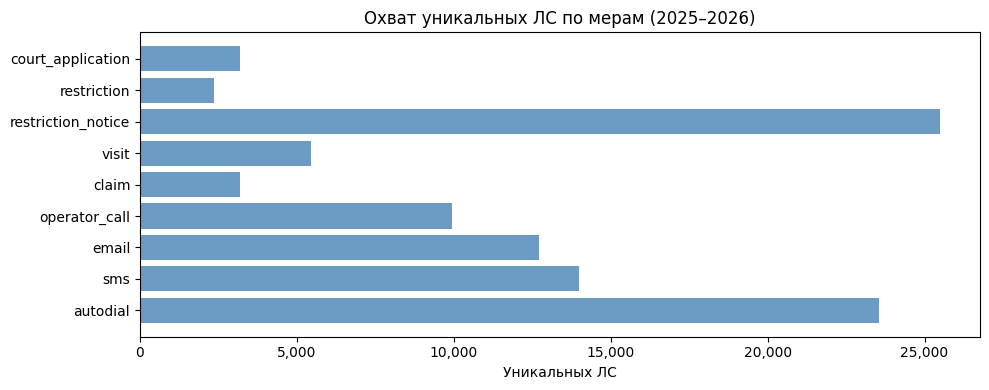

In [6]:
MEASURE_RU = {
    "autodial": "Автодозвон",
    "sms": "СМС",
    "email": "E-mail",
    "operator_call": "Обзвон оператором",
    "claim": "Претензия",
    "visit": "Выезд",
    "restriction_notice": "Увед. об ограничении",
    "restriction": "Ограничение",
    "court_application": "Суд. приказ",
}

MEASURE_META = {
    "autodial":           ("04 Автодозвон ХК.xlsx",      2.0),
    "sms":                ("06 СМС ХК.xlsx",              1.5),
    "email":              ("05 E-mail ХК.xlsx",           0.5),
    "operator_call":      ("07 Обзвон оператором ХК.xlsx", 60.0),
    "claim":              ("08 Претензия ХК.xlsx",        120.0),
    "visit":              ("09 Выезд к абоненту ХК.xlsx", 600.0),
    "restriction_notice": ("10 Уведомление о введении ограничения ХК.xlsx", 50.0),
    "restriction":        ("11 Ограничение ХК.xlsx",      250.0),
    "court_application":  ("12 Заявление о выдаче судебного приказа ХК.xlsx", 1200.0),
}

WINDOW_START = pd.Timestamp("2025-01-01")
WINDOW_END   = pd.Timestamp("2026-02-28")

# Количество событий по мерам
measure_counts = {}
for m_name, (fname, cost) in MEASURE_META.items():
    path = DATA_DIR / fname
    if not path.exists():
        continue
    df_m = pd.read_excel(path, header=1)
    df_m.columns = ["ls", "event_date"]
    df_m["event_date"] = pd.to_datetime(df_m["event_date"], errors="coerce")
    mask = (df_m["event_date"] >= WINDOW_START) & (df_m["event_date"] <= WINDOW_END)
    measure_counts[m_name] = {
        "n_events": mask.sum(),
        "n_unique_ls": df_m[mask]["ls"].nunique(),
        "cost_per_event": cost,
    }

mc_df = pd.DataFrame(measure_counts).T.reset_index().rename(columns={"index": "measure"})
mc_df["total_cost_estimate"] = mc_df["n_events"] * mc_df["cost_per_event"]
print(mc_df.rename(columns={
        "measure": "мера", "n_events": "событий", "n_unique_ls": "уник. ЛС",
        "cost_per_event": "стоим./соб.", "total_cost_estimate": "оценка затрат",}).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(mc_df["measure"].map(MEASURE_RU), mc_df["n_unique_ls"], color="steelblue", alpha=0.8)
ax.set_xlabel("Число уникальных лицевых счетов")
ax.set_title("Охват уникальных ЛС по мерам (2025–2026)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_measure_coverage.png", dpi=120)
plt.show()


## 3. Анализ целевых показателей: доля оплат в 30 дней по мерам


In [7]:
# Загружаем оплаты для анализа откликов
pay_raw = pd.read_csv(DATA_DIR / "03 Оплаты ХК.csv", dtype="string", sep=None, engine="python")
pay_raw.columns = [c.strip().replace("\ufeff", "") for c in pay_raw.columns]
pay_raw = pay_raw.rename(columns={"Номер": "ls_raw", "Дата оплаты": "date_raw", "Сумма": "amount_raw"})
pay_raw["ls"] = pd.to_numeric(pay_raw["ls_raw"], errors="coerce").astype("Int64")
pay_raw["date"] = pd.to_datetime(pay_raw["date_raw"], dayfirst=True, errors="coerce")
amount_clean = pay_raw["amount_raw"].str.replace(",", ".", regex=False).str.replace(" ", "", regex=False)
pay_raw["amount"] = pd.to_numeric(amount_clean, errors="coerce").fillna(0)
payments = pay_raw.dropna(subset=["ls", "date"])[["ls", "date", "amount"]]
pay_idx = payments.set_index("ls")

print(f"Оплат: {len(payments):,}, диапазон: {payments['date'].min().date()} – {payments['date'].max().date()}")

def compute_pay_rate_for_measure(fname: str, sample_n: int = 2000) -> dict:
    """Быстрая оценка доли оплат в 30 дн. по мере (сэмпл)."""
    path = DATA_DIR / fname
    df_m = pd.read_excel(path, header=1)
    df_m.columns = ["ls", "event_date"]
    df_m["event_date"] = pd.to_datetime(df_m["event_date"], errors="coerce")
    df_m = df_m.dropna()
    df_m = df_m[(df_m["event_date"] >= WINDOW_START) & (df_m["event_date"] <= pd.Timestamp("2026-02-01"))]
    df_m = df_m.drop_duplicates("ls")
    sample = df_m.sample(min(sample_n, len(df_m)), random_state=42)
    
    paid = []
    amounts = []
    for row in sample.itertuples(index=False):
        t0, t1 = row.event_date, row.event_date + pd.Timedelta(days=30)
        try:
            ls_pays = pay_idx.loc[row.ls]
            if isinstance(ls_pays, pd.Series):
                ls_pays = ls_pays.to_frame().T
            mask = (ls_pays["date"] >= t0) & (ls_pays["date"] <= t1)
            total = ls_pays.loc[mask, "amount"].sum()
        except KeyError:
            total = 0.0
        paid.append(int(total > 0))
        amounts.append(float(total))
    return {
        "n_sample": len(sample),
        "pay_rate_30d": np.mean(paid),
        "avg_recovered": np.mean(amounts),
        "median_recovered": np.median(amounts),
    }

print("\nОцениваем долю оплат в 30 дн. по каждой мере (сэмпл 2000 событий)...")
pay_rates = {}
for m_name, (fname, _) in MEASURE_META.items():
    path = DATA_DIR / fname
    if not path.exists():
        continue
    r = compute_pay_rate_for_measure(fname)
    pay_rates[m_name] = r
    print(f"  {m_name:25s}: доля_оплат_30д={r['pay_rate_30d']:.1%}, ср.возврат={r['avg_recovered']:.0f} руб.")

pr_df = pd.DataFrame(pay_rates).T.reset_index().rename(columns={"index": "measure"})


Оплат: 1,565,019, диапазон: 2024-12-30 – 2026-03-31

Вычисляем pay_rate для каждой меры (сэмпл 2000 событий)...
  autodial                 : pay_rate=48.1%, avg_recovered=963р
  sms                      : pay_rate=57.2%, avg_recovered=1639р
  email                    : pay_rate=54.2%, avg_recovered=1176р
  operator_call            : pay_rate=63.9%, avg_recovered=3437р
  claim                    : pay_rate=10.8%, avg_recovered=225р
  visit                    : pay_rate=40.8%, avg_recovered=1342р
  restriction_notice       : pay_rate=55.5%, avg_recovered=1727р
  restriction              : pay_rate=64.9%, avg_recovered=5711р
  court_application        : pay_rate=11.7%, avg_recovered=746р


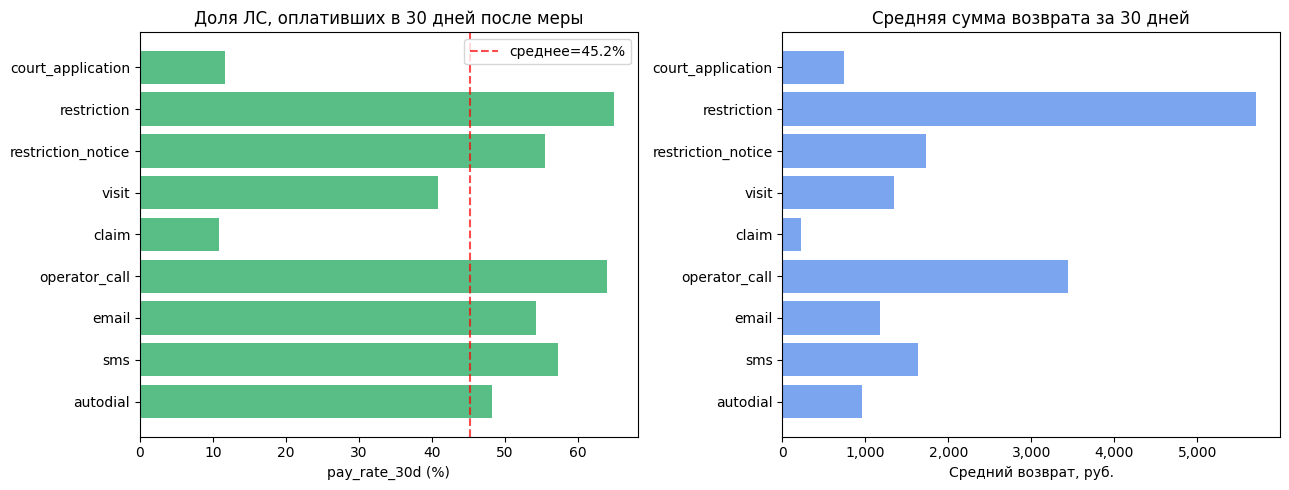


Вывод: меры с высоким pay_rate — не обязательно лучшие; важен UPLIFT (прирост vs control)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pay rate по мерам
ax = axes[0]
colors = plt.cm.RdYlGn([pr_df["pay_rate_30d"].values / pr_df["pay_rate_30d"].max()])
bars = ax.barh(pr_df["measure"].map(MEASURE_RU), pr_df["pay_rate_30d"] * 100, color="mediumseagreen", alpha=0.85)
ax.set_xlabel("Доля ЛС с оплатой в течение 30 дней, %")
ax.set_title("Доля ЛС, оплативших в 30 дней после меры")
ax.axvline(pr_df["pay_rate_30d"].mean() * 100, ls="--", color="red", alpha=0.7, label=f"среднее={pr_df['pay_rate_30d'].mean():.1%}")
ax.legend()

# Средний возврат
ax2 = axes[1]
ax2.barh(pr_df["measure"].map(MEASURE_RU), pr_df["avg_recovered"], color="cornflowerblue", alpha=0.85)
ax2.set_xlabel("Средний возврат, руб.")
ax2.set_title("Средняя сумма возврата за 30 дней")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.savefig(OUT_DIR / "eda_pay_rates.png", dpi=120)
plt.show()
print("\nВывод: высокая доля оплат в 30 д. не гарантирует лучшую меру; важен прирост (uplift) к контролю")


## 4. Метрики двухмодельного T-learner

После запуска `scripts/build_response_models.py` загружаем сводный файл (summary).


In [9]:
summary_path = OUT_DIR / "response_model_summary.csv"
if summary_path.exists():
    summary = pd.read_csv(summary_path)
    print("Метрики двухмодельного T-learner (μ1, μ0) по мерам:\n")
    cols_show = ["measure", "n_treated", "n_control", "pay_rate_treated", "pay_rate_control",
                 "naive_lift", "auc_mu1", "aupr_mu1", "auc_mu0", "propensity_auc"]
    cols_show = [c for c in cols_show if c in summary.columns]
    RU_COL = {
        "measure": "мера", "n_treated": "N_с_мерой", "n_control": "N_контроль",
        "pay_rate_treated": "доля_оплат_с_мерой", "pay_rate_control": "доля_оплат_контроль",
        "naive_lift": "наивн_лифт_п.п.", "auc_mu1": "AUC_mu1", "aupr_mu1": "AUPR_mu1",
        "auc_mu0": "AUC_mu0", "propensity_auc": "AUC_склонн.",
    }
    disp = summary[cols_show].rename(columns=RU_COL)
    pd.set_option("display.float_format", "{:.3f}".format)
    pd.set_option("display.max_columns", 20)
    pd.set_option("display.width", 200)
    print(disp.to_string(index=False))
else:
    print("⚠ Сводка не найдена — запустите scripts/build_response_models.py")


Метрики T-learner по мерам:

           measure  n_treated  n_control  pay_rate_treated  pay_rate_control  naive_lift  auc_mu1  aupr_mu1  auc_mu0  propensity_auc
          autodial      23555      47110             0.479             0.820      -0.340    0.888     0.886    0.941           0.994
               sms      13998      27996             0.577             0.822      -0.245    0.893     0.922    0.953           1.000
             email      12718      25436             0.534             0.778      -0.245    0.840     0.868    0.942           0.996
     operator_call       9938      19876             0.628             0.791      -0.163    0.911     0.942    0.922           0.999
             claim       3183       6366             0.109             0.766      -0.657    0.884     0.530    0.912           0.995
             visit       5281      10918             0.406             0.818      -0.412    0.968     0.956    0.941           1.000
restriction_notice      25492      50984

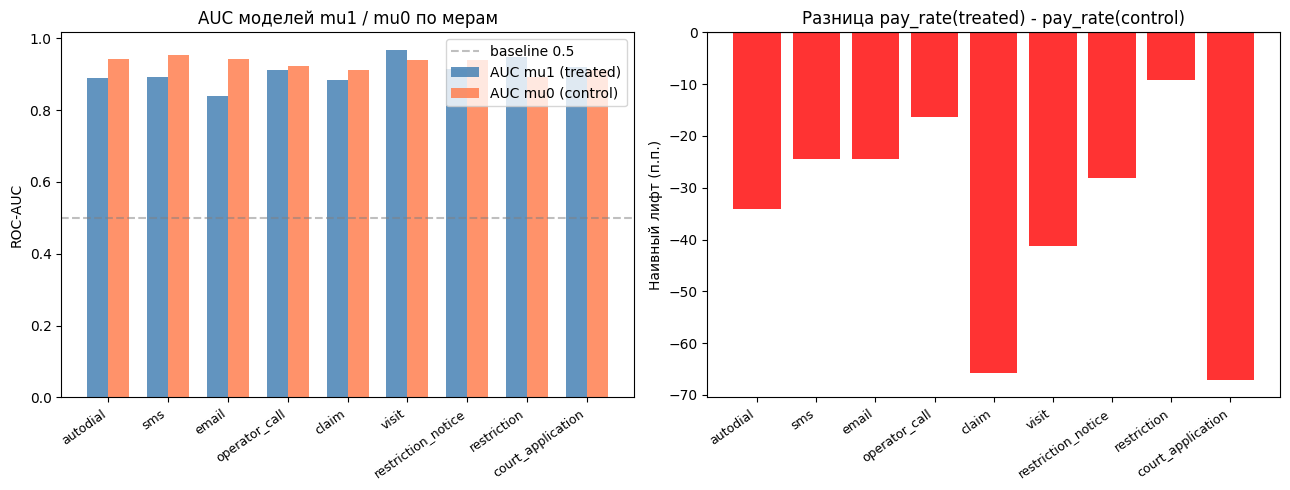

In [10]:
if summary_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ax = axes[0]
    x = np.arange(len(summary))
    w = 0.35
    ax.bar(x - w/2, summary["auc_mu1"], width=w, label="AUC μ1 (с мерой)", color="steelblue", alpha=0.85)
    ax.bar(x + w/2, summary["auc_mu0"], width=w, label="AUC μ0 (контроль)", color="coral", alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(summary["measure"].map(MEASURE_RU), rotation=35, ha="right", fontsize=9)
    ax.set_ylabel("ROC-AUC (площадь под кривой)")
    ax.set_title("AUC моделей μ1 / μ0 по мерам")
    ax.axhline(0.5, ls="--", color="gray", alpha=0.5, label="базовая линия 0,5")
    ax.legend()

    ax2 = axes[1]
    naive_lift_pct = summary["naive_lift"] * 100
    colors = ["green" if v > 0 else "red" for v in naive_lift_pct]
    ax2.bar(summary["measure"], naive_lift_pct, color=colors, alpha=0.8)
    ax2.set_xticklabels(summary["measure"].map(MEASURE_RU), rotation=35, ha="right", fontsize=9)
    ax2.set_ylabel("Наивный лифт (п.п.)")
    ax2.set_title("Разница долей оплат: с мерой − контроль, п.п.")
    ax2.axhline(0, color="black", linewidth=0.8)

    plt.tight_layout()
    plt.savefig(OUT_DIR / "model_quality_tlearner.png", dpi=120)
    plt.show()


## 5. Матрица полезности: анализ по сегментам


In [11]:
util_path = OUT_DIR / "utility_matrix.parquet"
if util_path.exists():
    util_df = pd.read_parquet(util_path)
    util_cols = [c for c in util_df.columns if c.startswith("utility_")]
    print(f"Матрица полезности (utility): {len(util_df):,} ЛС × {len(util_cols)} мер\n")

    # Средняя utility по сегментам
    seg_util = util_df.groupby("segment")[util_cols].mean().round(1)
    seg_util.index = [f"Сег. {i}: {SEGMENT_NAMES.get(i, '?')}" for i in seg_util.index]
    seg_util.columns = [c.replace("utility_", "") for c in seg_util.columns]
    print("Средняя полезность U(i, м) по сегментам:")
    print(seg_util.to_string())
else:
    print("⚠ Файл utility_matrix.parquet не найден — запустите scripts/build_response_models.py")
    util_df = None
    util_cols = []


Матрица utility: 136,620 ЛС × 9 мер

Средняя utility(i,m) по сегментам:
                                                       autodial     sms   email  operator_call    claim    visit  restriction_notice  restriction  court_application
Seg 0: Хроническая просрочка (Суд)                        1.100  19.800   9.300        -14.700 -112.400 -582.500             -24.200     -200.600          -1188.700
Seg 1: Средняя задолженность (Уведомление огр.)           3.800  60.600  -8.200         88.400 -162.900 -474.800              13.000      -45.700          -1239.900
Seg 2: Временные трудности (высокая ДЗ, хор. история)  -205.000 387.500 -34.800        559.900 -881.100 -242.600             181.300      -58.700          -1798.900
Seg 3: Незначительная задолженность                     -65.700   5.400 -77.000        -38.800 -205.000 -622.000             -48.300     -265.000          -1263.200
Seg 4: Без долга                                         18.000  36.600  19.900         -9.300 -118.300

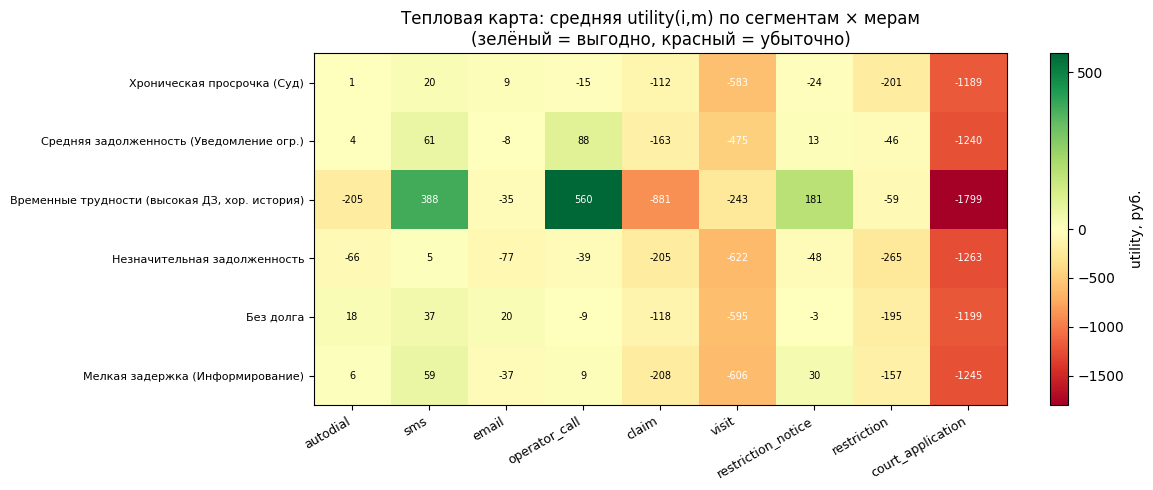


Интерпретация: utility > 0 означает, что мера экономически оправдана для данного сегмента


In [12]:
if util_df is not None and util_cols:
    import matplotlib.colors as mcolors

    seg_util_raw = util_df.groupby("segment")[util_cols].mean()
    seg_util_raw.index = [SEGMENT_NAMES.get(i, f"Сег. {i}") for i in seg_util_raw.index]
    seg_util_raw.columns = [MEASURE_RU.get(c.replace("utility_", ""), c.replace("utility_", "")) for c in seg_util_raw.columns]

    fig, ax = plt.subplots(figsize=(12, 5))
    vmax = seg_util_raw.values.max()
    vmin = seg_util_raw.values.min()
    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=max(vmax, 1))
    im = ax.imshow(seg_util_raw.values, cmap="RdYlGn", norm=norm, aspect="auto")
    ax.set_xticks(range(len(seg_util_raw.columns)))
    ax.set_xticklabels(seg_util_raw.columns, rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(len(seg_util_raw.index)))
    ax.set_yticklabels(seg_util_raw.index, fontsize=8)
    ax.set_title("Тепловая карта: средняя полезность по сегментам и мерам\n(зелёный = выгодно, красный = убыточно)")
    plt.colorbar(im, ax=ax, label="Полезность, руб.")

    # Подписи значений
    for i in range(len(seg_util_raw.index)):
        for j in range(len(seg_util_raw.columns)):
            val = seg_util_raw.iloc[i, j]
            color = "white" if abs(val) > vmax * 0.5 else "black"
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=7, color=color)

    plt.tight_layout()
    plt.savefig(OUT_DIR / "utility_heatmap.png", dpi=130)
    plt.show()
    print("\nИнтерпретация: полезность > 0 означает, что мера экономически оправдана для данного сегмента")


## 6. Прирост (uplift) по сегментам: лучшая мера для каждого ЛС


Распределение лучших мер по сегментам (количество ЛС):
best_measure                                    autodial  claim  court_application  email  operator_call  restriction  restriction_notice    sms  visit
Хроническая просрочка (Суд)                          169     52                  4   2182            259          147                 149    286      7
Средняя задолженность (Уведомление огр.)             468     73                  2   1585           1853         1447                 545   1339     68
Временные трудности (высокая ДЗ, хор. история)       140     11                  8    150            412          243                 135    540     92
Незначительная задолженность                        1409    184                  1   5789           4275          430                4225  68112     11
Без долга                                           1491     22                  0  11686           1645          458                1453   9528      0
Мелкая задержка (Информирование) 

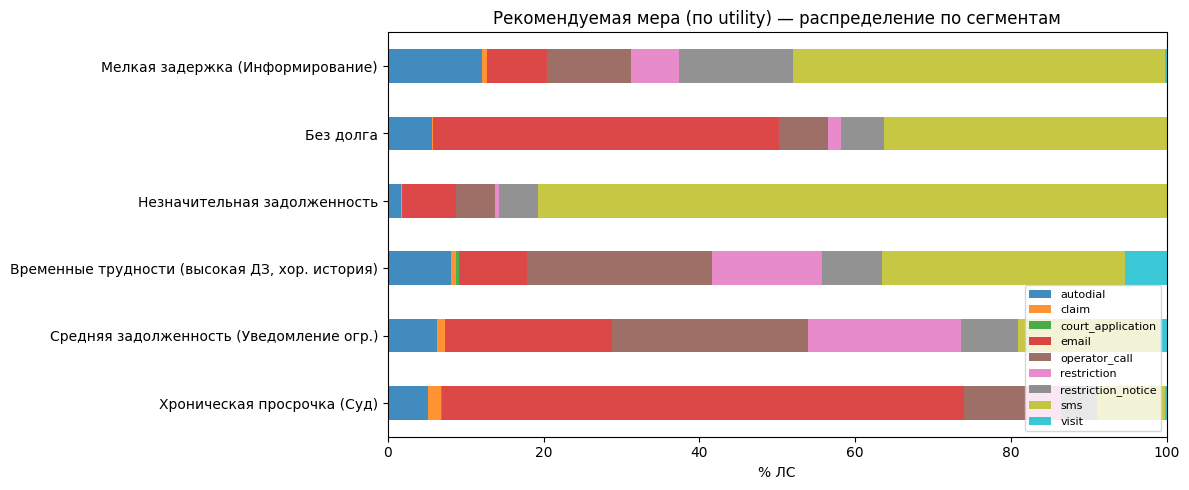

In [13]:
if util_df is not None and util_cols:
    # Лучшая мера по utility для каждого ЛС
    util_df["best_measure"] = util_df[util_cols].idxmax(axis=1).str.replace("utility_", "")
    util_df["best_utility"] = util_df[util_cols].max(axis=1)

    # Распределение топ-мер по сегментам
    seg_top = util_df.groupby(["segment", "best_measure"]).size().unstack(fill_value=0)
    seg_top.index = [SEGMENT_NAMES.get(i, f"Сег. {i}") for i in seg_top.index]

    print("Распределение лучших мер по сегментам (количество ЛС):")
    print(seg_top.rename(columns=MEASURE_RU).to_string())

    fig, ax = plt.subplots(figsize=(12, 5))
    seg_top_ru = seg_top.rename(columns=MEASURE_RU)
    seg_top_pct = seg_top_ru.div(seg_top_ru.sum(axis=1), axis=0) * 100
    seg_top_pct.plot(kind="barh", stacked=True, ax=ax, colormap="tab10", alpha=0.85)
    ax.set_xlabel("% ЛС")
    ax.set_title("Рекомендуемая мера (по полезности) — распределение по сегментам")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "best_measure_per_segment.png", dpi=120)
    plt.show()


## 7. Диагностика перекрытия (overlap) по скору склонности (propensity)

Проверяем, что группы с мерой и контролём перекрываются в пространстве признаков (условие *positivity* / overlap).
Если перекрытия мало, оценки прироста (uplift) будут ненадёжными.


In [14]:
import joblib

# Проверяем overlap на одной из мер (sms — самая массовая)
prop_path = MODELS_DIR / "propensity_sms.joblib"
train_path = OUT_DIR / "response_train_sms.parquet"

if prop_path.exists() and train_path.exists():
    prop_model = joblib.load(prop_path)
    train_df = pd.read_parquet(train_path)

    NUM_FEATS = [c for c in [
        "DZ_current", "avg_accrual_12m", "payment_ratio_12m", "payment_ratio_3m",
        "dz_trend_slope_6m", "log1p_DZ_current", "days_since_last_payment",
        "n_measures_12m", "response_rate_informational"
    ] if c in train_df.columns]
    CAT_FEATS = [c for c in ["has_phone", "has_ebill", "stage_reached", "settlement_type"] if c in train_df.columns]

    from sklearn.preprocessing import LabelEncoder
    all_cols = NUM_FEATS + CAT_FEATS
    df_clean = train_df.dropna(subset=all_cols)
    X_parts = [df_clean[NUM_FEATS].values.astype(np.float32)]
    for col in CAT_FEATS:
        le = LabelEncoder()
        X_parts.append(le.fit_transform(df_clean[col].fillna("Unknown").astype(str)).reshape(-1, 1))
    X = np.hstack(X_parts)
    prop_scores = prop_model.predict(X)

    treated_mask = df_clean["treatment"] == 1
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(prop_scores[treated_mask], bins=50, alpha=0.6, label="С мерой (СМС)", color="steelblue", density=True)
    ax.hist(prop_scores[~treated_mask], bins=50, alpha=0.6, label="Контроль (без меры)", color="coral", density=True)
    ax.set_xlabel("Скор склонности e(X) = P(T=1|X)")
    ax.set_ylabel("Плотность")
    ax.set_title("Перекрытие: мера «СМС»\n(хорошо, если кривые перекрываются)")
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / "propensity_overlap_sms.png", dpi=120)
    plt.show()

    # Доля treated с extreme propensity (< 0.05 или > 0.95)
    extreme_frac = ((prop_scores < 0.05) | (prop_scores > 0.95)).mean()
    print(f"Доля наблюдений с экстремальным скором склонности (propensity) (< 0.05 или > 0.95): {extreme_frac:.1%}")
    if extreme_frac > 0.2:
        print("⚠ Высокий процент экстремальных propensity — смещение отбора существенное")
        print("  Рекомендация: использовать DR-learner или IPW с усечением e(X) в [0,05; 0,95]")
    else:
        print("✓ Перекрытие приемлемо — оценки T-learner достаточно устойчивы")
else:
    print("⚠ Модели не найдены — запустите scripts/build_response_models.py")


[LightGBM] [Fatal] The number of features in data (13) is not the same as it was in training data (46).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.


LightGBMError: The number of features in data (13) is not the same as it was in training data (46).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.

## 8. Итоги и следующие шаги

**Что сделано:**
- T-learner по каждой мере: `mu1(X)` и `mu0(X)` (LightGBM, 5-fold CV)
- Модель склонности: `e(X) = P(T=1|X)` для оценки смещения отбора
- Матрица `utility(i,m)` = `uplift * expected_recovery - cost - risk_penalty`
- Разведочный анализ: доли оплат и охват по мерам

**Ограничения (честно):**
1. **Одна фича-матрица**: признаки на снапшот 2026-02-01, а меры были раньше. Это не «чистый» предсказательный сценарий — признаки отражают состояние после части воздействий. Для прода нужна историческая фича-матрица по каждому месяцу.
2. **Неслучайное назначение мер**: кому применяли выезд/суд — не случайно. Перекрытие по propensity может быть слабым; для дорогих мер целесообразен DR-learner (см. EconML, класс `LinearDRLearner`).
3. **Контроль**: сэмпл из должников без меры; реальный контрфакт труднее (возможно, мера просто «не дошла» по очереди).
4. **Целевая метрика**: `pay_30d` бинарный — не отражает частичные оплаты и эффект на горизонте 60–90 дней.

**Следующий шаг — п. 2.3 (Scorer + п. 3 «Optimizer»):**
- взять `utility_matrix.csv` на вход
- применить фильтры «Приложение №1» (доступность мер)
- запустить MILP (OR-Tools) в лимитах «Приложения №2»
- сформировать `monthly_plan.csv`
